# 03. Find groups of destination airports (Task 3)

**Question this notebook answers.** Q2 from `01_clean.ipynb`: which airports are the most and least reliable? Instead of ranking 118 airports one by one, we let k-means put the destination airports into a few groups with a similar *delay pattern*, so the agency can use one rule per group.

**Rules followed.**
- Only the **training months, January to September 2023** are used to build the groups (decision D16). The groups are later used as a model feature, so using October to December here would leak the test part.
- Only destinations with **at least 100 flights in January to September** are clustered. The others get the label `small` and are not dropped.
- `random_state=42` everywhere.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from utils import *

set_seed()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

fl = pd.read_parquet(PROC / "flights_clean.parquet")
ap = pd.read_parquet(PROC / "airports_clean.parquet")
tr = fl[fl.month.isin(TRAIN_MONTHS)].copy()
assert len(tr) == 330_883
print(f"training flights: {len(tr):,}; destinations in all 2023 flights: {fl.dest.nunique()}; in training: {tr.dest.nunique()}")

training flights: 330,883; destinations in all 2023 flights: 118; in training: 118


## 1. One row per destination airport

Each airport becomes one row of numbers. The columns, and why each one is there:

| Column | What it is | Why |
| --- | --- | --- |
| `late_rate` | share of flights late (>15 min) or cancelled (the target of prediction 1) | the main reliability number |
| `cancel_rate` | share of flights cancelled | clients who must be rebooked: a different problem from lateness |
| `mean_dep_delay` | mean departure delay in minutes of departed flights, each delay **clipped at the training 99th percentile** | a few 30-hour delays must not decide a group on their own |
| `late_rate_morning` (hours 5-9), `late_rate_midday` (10-14), `late_rate_afternoon` (15-18), `late_rate_evening` (19-23) | late rate within a part of the day | delays build up through the day (Task 2), so *when* an airport is bad matters. Four bands instead of 19 hours because hourly rates are noisy for airports with a few hundred flights |

Used only to **describe** the groups, not to build them: distance, flights per month, main origin, main airlines.

In [2]:
p99 = tr.dep_delay.astype(float).quantile(0.99)
print(f"training 99th percentile of dep_delay: {p99:.0f} minutes (delays are clipped here)")
tr["delay_clipped"] = tr.dep_delay.astype(float).clip(upper=p99)
tr["band"] = pd.cut(tr.hour.astype(int), [4, 9, 14, 18, 23], labels=["morning", "midday", "afternoon", "evening"])

air = tr.groupby("dest").agg(flights=("late", "size"), late_rate=("late", "mean"), cancel_rate=("cancelled", "mean"),
                             mean_dep_delay=("delay_clipped", "mean"), distance=("distance", "mean"))
bands = tr.pivot_table(index="dest", columns="band", values="late", aggfunc="mean", observed=True)
bands.columns = ["late_rate_" + c for c in bands.columns]
air = air.join(bands)
print(f"{len(air)} destinations in training; {(air.flights >= 100).sum()} have at least 100 flights")
small_dests = air.index[air.flights < 100].tolist()
air = air[air.flights >= 100].copy()
FIT = ["late_rate", "cancel_rate", "mean_dep_delay", "late_rate_morning", "late_rate_midday", "late_rate_afternoon", "late_rate_evening"]
missing_bands = air[FIT].isna().sum()
print("airports with no flight at all in a part of the day:"); display(missing_bands[missing_bands > 0].to_frame("airports").T)

training 99th percentile of dep_delay: 250 minutes (delays are clipped here)
118 destinations in training; 109 have at least 100 flights
airports with no flight at all in a part of the day:


,late_rate_morning,late_rate_midday,late_rate_afternoon,late_rate_evening
airports,17,7,7,19


**Empty parts of the day.** Some airports have no flight at all in one part of the day (for example only one flight a day, in the morning). Their late rate for that part is undefined. We fill it with the **airport's own overall late rate**: it says "no extra information about this part of the day" and does not invent a pattern. The consequence, which we check later, is that airports with a single daily flight look flat across the day.

In [3]:
air["bands_filled"] = air[FIT].isna().sum(axis=1)
for c in FIT:
    air[c] = air[c].fillna(air.late_rate)
assert air[FIT].notna().all().all()
print(f"{(air.bands_filled > 0).sum()} of {len(air)} airports had at least one empty part of the day (filled)")
display(air[FIT + ["flights"]].describe().loc[["min", "50%", "max"]].round(3))

34 of 109 airports had at least one empty part of the day (filled)


,late_rate,cancel_rate,mean_dep_delay,late_rate_morning,late_rate_midday,late_rate_afternoon,late_rate_evening,flights
min,0.122,0.000,0.927,0.000,0.000,0.000,0.087,108.0
50%,0.243,0.034,12.613,0.146,0.191,0.294,0.367,1629.0
max,0.625,0.120,54.566,0.625,0.703,1.000,0.637,14710.0


## 2. Scale the columns

The columns have different units (a rate between 0 and 1, minutes up to about 50). k-means measures distances, so without scaling the minutes column would decide everything. `StandardScaler` gives each column mean 0 and standard deviation 1. It is fitted on the airport table itself, which is made only of training flights.

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(air[FIT])
print("scaled shape:", X.shape, "| column means after scaling:", np.round(X.mean(axis=0), 6).tolist()[:3], "...")

scaled shape: (109, 7) | column means after scaling: [-0.0, 0.0, -0.0] ...


## 3. Choose the number of groups k

For k = 2 to 10 we run k-means (`n_init=20`, `random_state=42`) and look at two numbers:
- **inertia** (elbow): how tight the groups are. It always falls as k grows; we look for where the fall slows down.
- **silhouette**: from -1 to 1, how well each airport fits its own group compared with the nearest other group. Higher is better.

Common sense rules from the plan: no group with fewer than 5 airports unless it is a clear extreme, and every group must be describable in words.

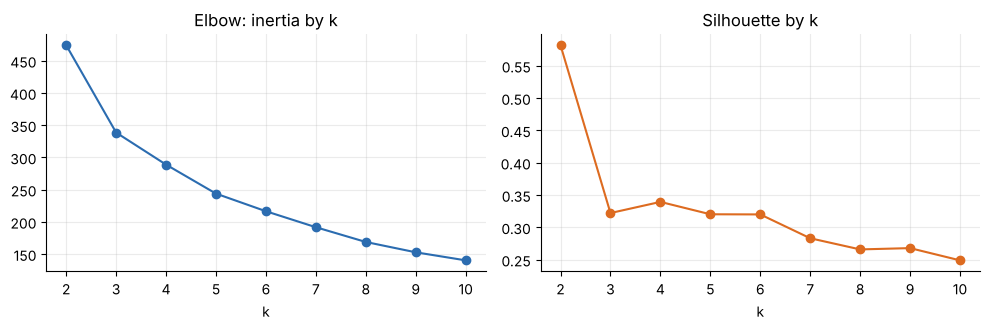

,inertia,silhouette,smallest_group,sizes
k,,,,
2,474.094,0.582,9,"[100, 9]"
3,338.556,0.322,7,"[57, 45, 7]"
4,288.781,0.339,3,"[3, 54, 45, 7]"
5,243.783,0.320,3,"[15, 43, 7, 3, 41]"
6,216.433,0.320,1,"[41, 14, 6, 3, 44, 1]"
7,191.635,0.283,1,"[36, 13, 6, 40, 1, 3, 10]"
8,168.733,0.266,1,"[17, 12, 38, 6, 3, 30, 2, 1]"
9,152.712,0.268,1,"[36, 29, 6, 10, 3, 9, 1, 1, 14]"
10,140.216,0.249,1,"[1, 20, 6, 13, 3, 28, 19, 1, 10, 8]"


In [5]:
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(X, km.labels_),
                     smallest_group=int(np.bincount(km.labels_).min()), sizes=np.bincount(km.labels_).tolist()))
ks = pd.DataFrame(rows).set_index("k")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ks.index, ks.inertia, marker="o", color="#2b6cb0"); ax[0].set_title("Elbow: inertia by k"); ax[0].set_xlabel("k")
ax[1].plot(ks.index, ks.silhouette, marker="o", color="#dd6b20"); ax[1].set_title("Silhouette by k"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
display(ks.round(3))

**Reading the plots.**
- k = 2 has the highest silhouette, but it splits the airports into 100 and 9: one big blob and a few extreme airports. It tells the business almost nothing.
- From k = 4 on, a group of only 3 airports appears (and more tiny groups later), which breaks the "at least 5 airports" rule.
- k = 3 keeps three groups, the smallest has 7 airports, and the elbow bends here (the drop in inertia from k=2 to k=3 is large, the drops after are smaller).

**Choice: k = 3.** One honest warning: a silhouette of 0.32 means the airports form a continuum rather than clearly separated clusters. The groups are a useful way to cut the airports into pieces, not a law of nature. Below we check that they are stable and that the three groups can be described.

In [6]:
K = 3
final = KMeans(K, n_init=20, random_state=SEED).fit(X)
aris = [adjusted_rand_score(final.labels_, KMeans(K, n_init=20, random_state=s).fit_predict(X)) for s in range(10)]
print("Adjusted Rand index between the chosen run and 10 runs with other seeds:", np.round(aris, 3).tolist())
print(f"minimum {min(aris):.3f} (1 = identical groups, the plan asks for at least 0.9)")
assert min(aris) >= 0.9

Adjusted Rand index between the chosen run and 10 runs with other seeds: [1.0, 1.0, 1.0, 0.965, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
minimum 0.965 (1 = identical groups, the plan asks for at least 0.9)


## 4. Describe the groups in numbers

k-means numbers its groups 0, 1, 2 at random. We renumber them from **best to worst `late_rate`** so that `G1` is always the most reliable group. The names are written after reading the table below, not before.

In [7]:
air["raw"] = final.labels_
order = air.groupby("raw").late_rate.mean().sort_values().index.tolist()
air["dest_group"] = air.raw.map({r: f"G{i + 1}" for i, r in enumerate(order)})
air = air.drop(columns="raw")

# group by origin / main airline, for description only
tr = tr.merge(air[["dest_group"]], left_on="dest", right_index=True, how="left")
inGrp = tr[tr.dest_group.notna()]
share_origin = pd.crosstab(inGrp.dest_group, inGrp.origin, normalize="index").mul(100).round(1).add_prefix("% from ")
top_carrier = inGrp.groupby("dest_group").carrier.agg(lambda s: ", ".join(f"{c} {100*n/len(s):.0f}%" for c, n in s.value_counts().head(3).items()))

summary = air.groupby("dest_group").agg(airports=("flights", "size"), flights=("flights", "sum"),
          **{c: (c, "mean") for c in FIT}, distance=("distance", "mean"))
display(summary.round(3))
display(share_origin)
display(top_carrier.to_frame("three biggest airlines (share of the group's flights)"))
for g, d in air.groupby("dest_group"):
    print(g, "five biggest airports by flights:", ", ".join(f"{i} ({r.flights:,})" for i, r in d.nlargest(5, "flights").iterrows()))

,airports,flights,late_rate,cancel_rate,mean_dep_delay,late_rate_morning,late_rate_midday,late_rate_afternoon,late_rate_evening,distance
dest_group,,,,,,,,,,
G1,57,101287,0.212,0.043,8.699,0.148,0.152,0.239,0.284,588.198
G2,45,226896,0.278,0.026,16.910,0.149,0.245,0.390,0.423,1425.511
G3,7,2374,0.531,0.034,41.476,0.496,0.476,0.573,0.547,2134.421


origin,% from EWR,% from JFK,% from LGA
dest_group,,,
G1,26.4,26.1,47.4
G2,34.3,32.1,33.5
G3,23.2,76.8,0.0


,three biggest airlines (share of the group's flights)
dest_group,
G1,"YX 51%, 9E 30%, UA 7%"
G2,"UA 23%, DL 20%, B6 19%"
G3,"B6 77%, UA 23%"


G1 five biggest airports by flights: RDU (8,850), DCA (7,395), PIT (6,114), CMH (5,824), IND (5,543)
G2 five biggest airports by flights: BOS (14,710), ORD (13,766), MCO (13,244), ATL (13,180), MIA (12,097)
G3 five biggest airports by flights: BQN (792), SMF (546), ONT (273), PSE (257), ABQ (189)


In [8]:
g_small = air[air.dest_group == air.dest_group.value_counts().idxmin()]
print("the smallest group, airport by airport:")
display(g_small[["flights", "late_rate", "cancel_rate", "mean_dep_delay", "bands_filled"]].round(3).sort_values("flights", ascending=False))

the smallest group, airport by airport:


,flights,late_rate,cancel_rate,mean_dep_delay,bands_filled
dest,,,,,
BQN,792,0.468,0.032,32.030,0
SMF,546,0.478,0.029,34.085,2
ONT,273,0.538,0.026,42.733,2
PSE,257,0.568,0.035,47.452,3
ABQ,189,0.577,0.048,43.994,3
SJC,189,0.466,0.021,35.476,3
RNO,128,0.625,0.047,54.566,1


**What the table says.** (numbers are from the cells above)
- **G1** is the shortest-haul group (mean distance about 590 miles) and the best on delay: it has the lowest late rate and the lowest mean delay, flat until the afternoon. Its one weakness is that it has the **highest cancellation rate** (4.3%). Half of its flights are flown by YX and 30% by 9E, the two airlines that Task 2 found to have the most cancellations on bad days.
- **G2** is the long-haul main group, with most of the flights. Mornings are as good as G1 (about 15% late), but the late rate climbs to 24% at midday, 39% in the afternoon and 42% in the evening.
- **G3** is a handful of airports (77% of its flights leave from JFK, 77% are flown by B6) with a late rate above 50% in every part of the day and a mean delay of about 41 minutes. Most have few flights a day: part of their day bands were filled with the airport's overall rate (column `bands_filled`), so "bad all day" is partly a result of that choice. The overall rate, the mean delay and the cancel rate are real measurements.

In [9]:
# Names are chosen after reading the numbers above. Assertions make the notebook fail if the data ever disagrees with a name.
NAMES = {"G1": "Short-haul: mild delays, most cancellations",
         "G2": "Main long-haul: delays build up through the day",
         "G3": "Chronic delays on few flights"}
s = summary
assert s.loc["G1", "cancel_rate"] == s.cancel_rate.max() and s.loc["G1", "distance"] == s.distance.min()
assert s.loc["G2", "flights"] == s.flights.max()
assert s.loc["G2", "late_rate_evening"] - s.loc["G2", "late_rate_morning"] > 0.2
assert s.loc["G3", "late_rate"] > 0.5 and s.loc["G3", "airports"] < 10
air["dest_group_name"] = air.dest_group.map(NAMES)
print(pd.Series(NAMES).to_string())

G1        Short-haul: mild delays, most cancellations
G2    Main long-haul: delays build up through the day
G3                      Chronic delays on few flights


## 5. Picture: the groups in two dimensions

PCA squeezes the 7 scaled columns into 2 so we can draw the airports. This picture is only for looking: the groups were built on all 7 columns, not on these two.

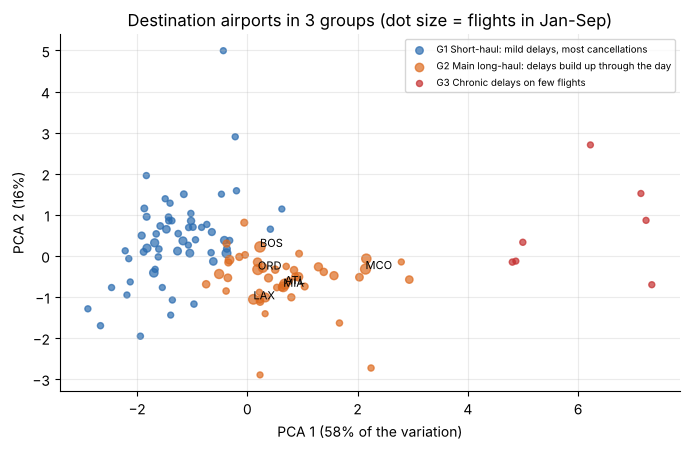

In [10]:
pca = PCA(2, random_state=SEED).fit(X)
P = pca.transform(X)
fig, ax = plt.subplots(figsize=(7, 4.6))
for g, col in zip(sorted(air.dest_group.unique()), ["#2b6cb0", "#dd6b20", "#c53030"]):
    m = (air.dest_group == g).values
    ax.scatter(P[m, 0], P[m, 1], s=18 + air.flights.values[m] / 400, alpha=0.7, color=col, label=f"{g} {NAMES[g]}")
for i in air.nlargest(6, "flights").index:
    j = air.index.get_loc(i); ax.annotate(i, P[j], fontsize=8)
ax.set_xlabel(f"PCA 1 ({100*pca.explained_variance_ratio_[0]:.0f}% of the variation)"); ax.set_ylabel(f"PCA 2 ({100*pca.explained_variance_ratio_[1]:.0f}%)")
ax.set_title("Destination airports in 3 groups (dot size = flights in Jan-Sep)"); ax.legend(fontsize=7, loc="best")
plt.tight_layout(); plt.show()

## 6. Save the group of every destination

`groups_airport.parquet` has one row per destination airport that appears in the flights file. Airports with fewer than 100 training flights, **and any airport that only appears in October to December**, get the label `small` (they have no training history to be grouped on). Tasks 4, 5 and 7 read this file.

In [11]:
all_dests = pd.DataFrame({"dest": sorted(fl.dest.unique())})
out = all_dests.merge(air.reset_index()[["dest", "dest_group", "dest_group_name"] + FIT + ["flights", "distance"]], on="dest", how="left")
out["dest_group"] = out.dest_group.fillna("small")
out["dest_group_name"] = out.dest_group_name.fillna("Small airports (under 100 flights in Jan-Sep)")
out = out.rename(columns={"flights": "train_flights"})
out.to_parquet(PROC / "groups_airport.parquet", index=False)
chk = fl.merge(out[["dest", "dest_group"]], on="dest", how="left")
assert len(chk) == len(fl) and chk.dest_group.notna().all()
print(f"saved {len(out)} destinations; flights per group, whole year:")
display(chk.dest_group.value_counts().rename("flights").to_frame().T)
print("destinations labelled small:", (out.dest_group == "small").sum(), "(under 100 training flights:", len(small_dests), ")")

saved 118 destinations; flights per group, whole year:


dest_group,G2,G1,G3,small
flights,300475,131450,2982,445


destinations labelled small: 9 (under 100 training flights: 9 )


## 7. One row per group: name, size, what is typical, what to do

The actions use the three levers of the business (warn clients earlier, check connections, rebook). Each action is backed by a number from the table above.

In [12]:
g = summary
rows = []
act = {"G1": f"Rebooking readiness first: {100*g.loc['G1','cancel_rate']:.1f}% of these flights are cancelled (highest of the groups). Warning messages can wait until the afternoon: the morning late rate is only {100*g.loc['G1','late_rate_morning']:.0f}%.",
       "G2": f"Warn clients earlier for afternoon and evening flights (late rate {100*g.loc['G2','late_rate_afternoon']:.0f}% and {100*g.loc['G2','late_rate_evening']:.0f}%, against {100*g.loc['G2','late_rate_morning']:.0f}% in the morning) and check connections for evening arrivals. These are {100*g.loc['G2','flights']/g.flights.sum():.0f}% of the grouped flights.",
       "G3": f"Always send a warning and a connection check: late rate {100*g.loc['G3','late_rate']:.0f}% and mean delay {g.loc['G3','mean_dep_delay']:.0f} minutes, but only {int(g.loc['G3','flights']):,} flights in nine months, so treat the figure with care and re-check it every month."}
typ = {k: f"late {100*g.loc[k,'late_rate']:.1f}%, cancelled {100*g.loc[k,'cancel_rate']:.1f}%, mean delay {g.loc[k,'mean_dep_delay']:.1f} min, morning/evening late {100*g.loc[k,'late_rate_morning']:.0f}%/{100*g.loc[k,'late_rate_evening']:.0f}%, distance {g.loc[k,'distance']:.0f} miles" for k in g.index}
final_table = pd.DataFrame({"name": pd.Series(NAMES), "airports": g.airports, "flights (Jan-Sep)": g.flights.astype(int), "typical": pd.Series(typ), "what to do": pd.Series(act)})
final_table.index.name = "group"
pd.set_option("display.max_colwidth", 400)
display(final_table)

,name,airports,flights (Jan-Sep),typical,what to do
group,,,,,
G1,"Short-haul: mild delays, most cancellations",57,101287,"late 21.2%, cancelled 4.3%, mean delay 8.7 min, morning/evening late 15%/28%, distance 588 miles",Rebooking readiness first: 4.3% of these flights are cancelled (highest of the groups). Warning messages can wait until the afternoon: the morning late rate is only 15%.
G2,Main long-haul: delays build up through the day,45,226896,"late 27.8%, cancelled 2.6%, mean delay 16.9 min, morning/evening late 15%/42%, distance 1426 miles","Warn clients earlier for afternoon and evening flights (late rate 39% and 42%, against 15% in the morning) and check connections for evening arrivals. These are 69% of the grouped flights."
G3,Chronic delays on few flights,7,2374,"late 53.1%, cancelled 3.4%, mean delay 41.5 min, morning/evening late 50%/55%, distance 2134 miles","Always send a warning and a connection check: late rate 53% and mean delay 41 minutes, but only 2,374 flights in nine months, so treat the figure with care and re-check it every month."


**Summary.** Three groups of destination airports were found from Jan-Sep delay patterns (k = 3, stable across seeds, adjusted Rand index at least 0.9). The group of each airport is saved in `data/processed/groups_airport.parquet` and used as a feature in Task 5 and for the per-group tables in Tasks 4 and 7. Caveats: nine months of one year, only 109 of 118 airports are clustered, and the 7 airports of G3 are described by few flights.